# Série temporal de ações com PyTorch: tensores, Dataset e DataLoader

**Autor:** Renan Santos Mendes
**E-mail:** renansantosmendes@gmail.com

## 1. Instalação das bibliotecas

Nesta célula instalamos o `uv`, gerenciador de pacotes que usaremos no Colab, e em seguida a biblioteca `yfinance`, que baixa cotações históricas do Yahoo Finance, incluindo ações negociadas na B3.

In [ ]:
!pip install -q uv
!uv pip install --system -q yfinance

## 2. Importação das bibliotecas

Importamos o NumPy e o pandas para manipular os dados, o PyTorch para tensores e redes neurais, o `yfinance` para a coleta e o Matplotlib para os gráficos. Também fixamos a semente aleatória para que os resultados sejam reproduzíveis.

In [ ]:
import numpy as np
import pandas as pd
import torch
import yfinance as yf
import matplotlib.pyplot as plt
from torch import nn
from torch.utils.data import DataLoader, Dataset

torch.manual_seed(42)

## 2.1 Catálogo de tickers por área

Os tickers estão organizados em um dicionário, em que cada chave é uma área e cada valor é a lista de ações dessa área. Tickers brasileiros terminam em `.SA` e tickers americanos não têm sufixo.

In [ ]:
TICKERS_BY_AREA = {
    "petroleo_gas_energia": ["PETR4.SA", "PETR3.SA", "PRIO3.SA", "RAIZ4.SA"],
    "bancos_financeiro": ["ITUB4.SA", "BBDC4.SA", "BBAS3.SA", "SANB11.SA"],
    "mineracao_siderurgia": ["VALE3.SA", "CSNA3.SA", "GGBR4.SA"],
    "consumo": ["ABEV3.SA", "MGLU3.SA", "LREN3.SA"],
    "tecnologia_eua": ["AAPL", "MSFT", "NVDA", "GOOGL", "META"],
    "financeiro_eua": ["JPM", "BAC", "GS", "MS"],
    "energia_eua": ["XOM", "CVX", "COP"],
}

As funções abaixo mostram as áreas disponíveis e retornam os tickers de uma área escolhida, para que o aluno veja as opções antes de decidir.

In [ ]:
def list_tickers_by_area(
    tickers_by_area: dict[str, list[str]],
) -> None:
    """
    Print every area of the catalog together with its tickers.

    Parameters
    ----------
    tickers_by_area : dict[str, list[str]]
        Dictionary mapping each area name to its list of ticker symbols.

    Returns
    -------
    None
        The areas and tickers are printed to the output.

    Example
    -------
    >>> list_tickers_by_area({"consumo": ["ABEV3.SA"]})
    consumo: ABEV3.SA
    """
    for area_name, ticker_list in tickers_by_area.items():
        print(f"{area_name}: {', '.join(ticker_list)}")


def get_area_tickers(
    tickers_by_area: dict[str, list[str]],
    area_name: str,
) -> list[str]:
    """
    Return the list of tickers of a given area of the catalog.

    Parameters
    ----------
    tickers_by_area : dict[str, list[str]]
        Dictionary mapping each area name to its list of ticker symbols.
    area_name : str
        Name of the area whose tickers should be returned.

    Returns
    -------
    list[str]
        Ticker symbols that belong to the requested area.

    Raises
    ------
    KeyError
        If ``area_name`` is not a key of ``tickers_by_area``.
    """
    if area_name not in tickers_by_area:
        raise KeyError(
            f"Area '{area_name}' not found. "
            f"Options: {list(tickers_by_area)}"
        )
    return tickers_by_area[area_name]


list_tickers_by_area(TICKERS_BY_AREA)

petroleo_gas_energia: PETR4.SA, PETR3.SA, PRIO3.SA, RAIZ4.SA
bancos_financeiro: ITUB4.SA, BBDC4.SA, BBAS3.SA, SANB11.SA
mineracao_siderurgia: VALE3.SA, CSNA3.SA, GGBR4.SA
consumo: ABEV3.SA, MGLU3.SA, LREN3.SA
tecnologia_eua: AAPL, MSFT, NVDA, GOOGL, META
financeiro_eua: JPM, BAC, GS, MS
energia_eua: XOM, CVX, COP


Nesta célula o aluno escolhe a área e o ticker que serão usados em toda a prática. Se o ticker não pertencer à área escolhida, a célula avisa com um erro.

In [ ]:
SELECTED_AREA = "tecnologia_eua"
SELECTED_TICKER = "NVDA"

area_tickers = get_area_tickers(TICKERS_BY_AREA, SELECTED_AREA)
if SELECTED_TICKER not in area_tickers:
    raise ValueError(
        f"Ticker '{SELECTED_TICKER}' does not belong to '{SELECTED_AREA}'."
    )
print(f"Ativo escolhido: {SELECTED_TICKER} ({SELECTED_AREA})")

Ativo escolhido: NVDA (tecnologia_eua)


## 3. Coleta dos preços de fechamento

A função abaixo baixa a série diária de preços de fechamento do ticker escolhido entre duas datas. O ticker é definido pelas variáveis `SELECTED_AREA` e `SELECTED_TICKER` da seção anterior.

In [ ]:
def download_closing_prices(
    ticker: str,
    start_date: str,
    end_date: str,
) -> pd.Series:
    """
    Download the daily closing prices of a stock from Yahoo Finance.

    Parameters
    ----------
    ticker : str
        Stock ticker symbol, for example "PETR4.SA" for a B3 stock.
    start_date : str
        First date of the series in the "YYYY-MM-DD" format.
    end_date : str
        End date of the series in the "YYYY-MM-DD" format. The date
        itself is not included in the download.

    Returns
    -------
    pd.Series
        Daily closing prices indexed by date, without missing values.
    """
    raw_data = yf.download(
        ticker,
        start=start_date,
        end=end_date,
        auto_adjust=True,
        progress=False,
    )
    closing_column = raw_data["Close"]
    if isinstance(closing_column, pd.DataFrame):
        closing_column = closing_column.iloc[:, 0]
    return closing_column.dropna()


closing_prices = download_closing_prices(
    ticker=SELECTED_TICKER,
    start_date="2021-01-01",
    end_date="2026-11-11",
)
print("Quantidade de observações:", len(closing_prices))
closing_prices.head()

Quantidade de observações: 1471


,NVDA
Date,
2021-01-04,13.046198
2021-01-05,13.335953
2021-01-06,12.549760
2021-01-07,13.275516
2021-01-08,13.208611


In [ ]:
closing_prices.tail()

,NVDA
Date,
2026-11-04,200.130005
2026-11-05,181.600006
2026-11-06,186.639999
2026-11-09,178.669998
2026-11-10,168.889999


## 3.1 Visualização da série temporal

Antes de qualquer cálculo, o gráfico mostra como o preço se comporta ao longo do tempo. A função `plot_time_series` aceita cinco tipos de gráfico:

- `line`: preço de fechamento em escala linear.
- `log_scale`: mesmo preço, com escala logarítmica no eixo vertical.
- `rolling_mean`: preço com a média móvel de 20 dias, que suaviza as oscilações.
- `histogram`: distribuição dos preços, mostrando em que faixas eles mais aparecem.
- `returns`: retornos logarítmicos diários, que serão usados nas próximas seções.

In [ ]:
def plot_time_series(
    series: pd.Series,
    plot_type: str,
    ticker: str,
) -> None:
    """
    Plot a price series with the chart type chosen by the student.

    Parameters
    ----------
    series : pd.Series
        Closing prices indexed by date.
    plot_type : str
        Chart type. Accepted values are "line", "log_scale",
        "rolling_mean", "histogram" and "returns".
    ticker : str
        Ticker symbol used in the title of the chart.

    Returns
    -------
    None
        The chart is displayed with Matplotlib.

    Raises
    ------
    ValueError
        If ``plot_type`` is not one of the accepted values.

    Example
    -------
    >>> plot_time_series(closing_prices, "rolling_mean", "AAPL")
    """
    figure, axis = plt.subplots(figsize=(10, 4))
    if plot_type == "line":
        axis.plot(series.index, series.values)
        axis.set_ylabel("Preço")
    elif plot_type == "log_scale":
        axis.plot(series.index, series.values)
        axis.set_yscale("log")
        axis.set_ylabel("Preço (escala logarítmica)")
    elif plot_type == "rolling_mean":
        axis.plot(series.index, series.values, alpha=0.4, label="Preço")
        axis.plot(
            series.index,
            series.rolling(window=20).mean(),
            label="Média móvel de 20 dias",
        )
        axis.legend()
        axis.set_ylabel("Preço")
    elif plot_type == "histogram":
        axis.hist(series.values, bins=50)
        axis.set_xlabel("Preço")
        axis.set_ylabel("Frequência")
    elif plot_type == "returns":
        log_returns = np.log(series / series.shift(1)).dropna()
        axis.plot(log_returns.index, log_returns.values)
        axis.set_ylabel("Retorno logarítmico")
    else:
        plt.close(figure)
        raise ValueError(
            f"Unknown plot_type '{plot_type}'. Options: "
            "'line', 'log_scale', 'rolling_mean', 'histogram', 'returns'."
        )
    axis.set_title(f"{ticker} - {plot_type}")
    axis.grid(alpha=0.3)
    plt.show()

Escolha o tipo de gráfico alterando a variável `PLOT_TYPE` e execute a célula novamente. Os valores aceitos são `line`, `log_scale`, `rolling_mean`, `histogram` e `returns`.

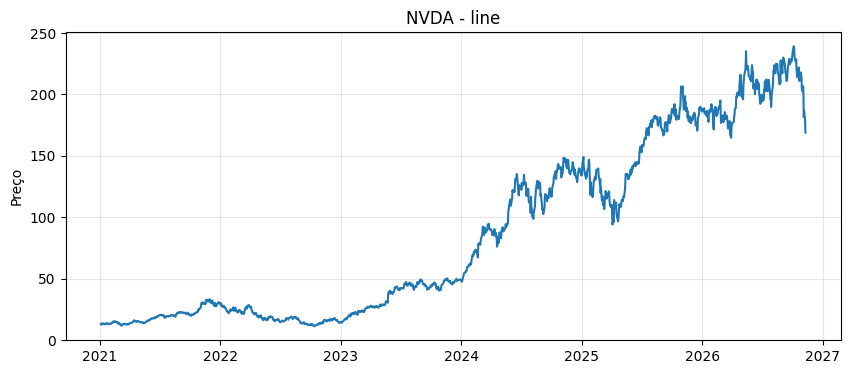

In [ ]:
PLOT_TYPE = "line"
plot_time_series(
    series=closing_prices,
    plot_type=PLOT_TYPE,
    ticker=SELECTED_TICKER,
)

## 4. Retornos logarítmicos e conversão para tensor

O retorno logarítmico de um dia é calculado por $r_t = \ln(P_t / P_{t-1})$, ou seja, o logaritmo da razão entre o preço de hoje e o preço de ontem. Ele tem propriedades estatísticas mais convenientes para modelagem do que o preço em si. A função abaixo faz esse cálculo com operações simples de vetores.

In [ ]:
price_values = closing_prices.to_numpy(dtype=np.float64)

In [ ]:
price_values[:]

array([ 13.04619789,  13.33595276,  12.54975986, ..., 186.63999939,
       178.66999817, 168.88999939], shape=(1471,))

In [ ]:
price_values[1:]

array([ 13.33595276,  12.54975986,  13.27551556, ..., 186.63999939,
       178.66999817, 168.88999939], shape=(1470,))

In [ ]:
price_values[:-1]

array([ 13.04619789,  13.33595276,  12.54975986, ..., 181.6000061 ,
       186.63999939, 178.66999817], shape=(1470,))

In [ ]:
log_return = np.log(price_values[1:] / price_values[:-1])

In [ ]:
log_return.mean()

np.float64(0.0017420073944410296)

In [ ]:
log_return.std()

np.float64(0.03161946494989572)

In [ ]:
def compute_log_returns(prices: pd.Series) -> np.ndarray:
    """
    Compute the daily log returns of a price series.

    The log return at time t is the natural logarithm of the ratio between
    the price at time t and the price at time t - 1. The output therefore
    has one element fewer than the input.

    Parameters
    ----------
    prices : pd.Series
        Price series in chronological order, with no missing values.

    Returns
    -------
    np.ndarray
        One-dimensional array with the log returns of the series.

    Example
    -------
    >>> compute_log_returns(pd.Series([100.0, 110.0]))
    array([0.09531018])
    """
    price_values = prices.to_numpy(dtype=np.float64)
    return np.log(price_values[1:] / price_values[:-1])


log_returns_array = compute_log_returns(closing_prices)
log_returns_tensor = torch.Tensor(log_returns_array)
print("Shape da série de retornos:", log_returns_tensor.shape)
print("Tipo dos dados:", log_returns_tensor.dtype)
print("Primeiros retornos:", log_returns_tensor[:5])

Shape da série de retornos: torch.Size([1470])
Tipo dos dados: torch.float32
Primeiros retornos: tensor([ 0.0220, -0.0608,  0.0562, -0.0051,  0.0256])


In [ ]:
log_returns_tensor.dtype

torch.float32

In [ ]:
log_returns_tensor.element_size()*8

32

In [ ]:
log_returns_tensor.shape

torch.Size([1470])

In [ ]:
log_returns_tensor.ndim

1

In [ ]:
log_returns_tensor.mean()

tensor(0.0017)

## 5. Conceitos básicos de tensores

Um tensor é uma estrutura multidimensional de números, com um `shape` (formato), um `dtype` (tipo dos dados) e um número de dimensões (`ndim`). Um escalar tem 0 dimensões, um vetor tem 1, uma matriz tem 2, e assim por diante. A série de retornos que criamos é um tensor de 1 dimensão. Abaixo vemos algumas operações simples sobre um tensor de exemplo.

In [ ]:
example_tensor = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
print("Formato:", example_tensor.shape)
print("Número de dimensões:", example_tensor.ndim)
print("Tipo:", example_tensor.dtype)
print("Soma de todos os elementos:", example_tensor.sum())
print("Média por coluna (dim=0):", example_tensor.mean(dim=0))
print("Multiplicação por escalar:", example_tensor * 2)
print("Soma elemento a elemento:", example_tensor + example_tensor)

Formato: torch.Size([2, 3])
Número de dimensões: 2
Tipo: torch.float32
Soma de todos os elementos: tensor(21.)
Média por coluna (dim=0): tensor([2.5000, 3.5000, 4.5000])
Multiplicação por escalar: tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
Soma elemento a elemento: tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])


## 6. Padronização e divisão em treino e teste

Os retornos diários são números pequenos, da ordem de 0,01. Para facilitar o treinamento, eles são padronizados (subtraindo a média e dividindo pelo desvio-padrão). A média e o desvio-padrão são calculados apenas com os primeiros 80% dos dias, que formam o período de treino. Usar o período de teste nesse cálculo faria o modelo receber informação do futuro.

A divisão respeita a ordem cronológica, sem embaralhar os dados.

In [ ]:
split_index = int(len(log_returns_tensor) * 0.8)

In [ ]:
int(len(log_returns_tensor)*0.8)

1176

In [ ]:
len(log_returns_tensor[:split_index])

1176

In [ ]:
len(log_returns_tensor[split_index:])

294

In [ ]:

RETURNS_MEAN = ...
RETURNS_STD = ...
standardized_returns = ...
train_returns = ...
test_returns = ...
print("Média do treino (retorno original):", RETURNS_MEAN.item())
print("Desvio-padrão do treino (retorno original):", RETURNS_STD.item())
print("Observações de treino:", train_returns.shape[0])
print("Observações de teste:", test_returns.shape[0])

## 7. Dataset de janela deslizante

Esta é a forma mais simples de transformar uma série temporal em um problema de aprendizado supervisionado. Com uma janela de 10 dias, a entrada `X` são os retornos dos dias 1 a 10 e o alvo `y` é o retorno do dia 11. Para criar a próxima amostra, a janela desliza um dia para frente.

A classe `Dataset` do PyTorch precisa implementar dois métodos: `__len__`, que informa quantas amostras existem, e `__getitem__`, que devolve uma amostra pelo índice.

In [ ]:
class SlidingWindowDataset(Dataset):
    """
    Dataset that turns a univariate time series into supervised samples.

    Each sample is a window of consecutive values used as input. The value
    that comes right after the window is the regression target.

    Parameters
    ----------
    series : torch.Tensor
        One-dimensional tensor with the time series values, in
        chronological order.
    window_size : int
        Number of consecutive values used as input in each sample.

    Example
    -------
    >>> series = torch.arange(6, dtype=torch.float32)
    >>> dataset = SlidingWindowDataset(series, window_size=3)
    >>> inputs, target = dataset[0]
    >>> inputs
    tensor([0., 1., 2.])
    >>> target
    tensor([3.])
    """

    def __init__(
        self,
        series: torch.Tensor,
        window_size: int,
    ) -> None:
        """
        Store the series and the window size used to build the samples.

        Parameters
        ----------
        series : torch.Tensor
            One-dimensional tensor with the time series values.
        window_size : int
            Number of consecutive values used as input in each sample.

        Returns
        -------
        None
        """
        ...

    def __len__(self) -> int:
        """
        Count how many windows can be extracted from the series.

        Returns
        -------
        int
            Number of samples available in the dataset.
        """
        return ...

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        """
        Return the input window and the target value at a given index.

        Parameters
        ----------
        index : int
            Position of the sample, starting at zero.

        Returns
        -------
        tuple[torch.Tensor, torch.Tensor]
            The input window with shape (window_size,) and the target
            value with shape (1,), the value right after the window.
        """
        window_end = ...
        inputs = ...
        target = ...
        return inputs, target

Agora criamos os datasets de treino e de teste com uma janela de 10 dias e inspecionamos uma amostra. Repare que a entrada tem formato `(10,)` e o alvo tem formato `(1,)`.

In [ ]:
WINDOW_SIZE = 10
train_dataset = ...
test_dataset = ...

print("Amostras de treino:", len(train_dataset))
print("Amostras de teste:", len(test_dataset))

sample_inputs, sample_target = train_dataset[0]

print("Formato da entrada:", sample_inputs.shape)
print("Formato do alvo:", sample_target.shape)
print("Entrada da primeira amostra:", sample_inputs)
print("Alvo da primeira amostra:", sample_target)

## 8. DataLoader

O `DataLoader` agrupa as amostras em lotes (*batches*) e, se necessário, as embaralha a cada época. No treino usamos `shuffle=True`, para que o modelo não aprenda a ordem exata das janelas. No teste mantemos `shuffle=False`, para facilitar a comparação com a série real.

In [ ]:
BATCH_SIZE = 32
train_loader = ...
test_loader = ...

batch_inputs, batch_targets = next(iter(train_loader))

print("Formato do lote de entradas:", batch_inputs.shape)
print("Formato do lote de alvos:", batch_targets.shape)

## 9. Modelo: rede neural com camadas ocultas do mesmo tamanho

A rede recebe a janela de 10 valores e a passa por uma sequência de camadas ocultas, todas com o mesmo número de neurônios. Cada camada oculta é seguida de uma ativação ReLU, que permite à rede aprender relações não lineares. Ao final, uma camada linear produz uma única previsão.

A classe abaixo cria essa estrutura a partir de dois parâmetros: o tamanho das camadas ocultas e a quantidade de camadas.

In [ ]:
class FeedForwardForecaster(nn.Module):
    """
    Feed-forward neural network that predicts the next value of a window.

    The network receives the input window and passes it through a number of
    hidden layers that all have the same size, each followed by a ReLU
    activation. A final linear layer produces one prediction per sample.

    Parameters
    ----------
    window_size : int
        Number of input values received by the network in each sample.
    hidden_size : int
        Number of neurons in each hidden layer.
    number_of_hidden_layers : int
        Number of hidden layers between the input and the output.

    Example
    -------
    >>> model = FeedForwardForecaster(
    ...     window_size=10,
    ...     hidden_size=16,
    ...     number_of_hidden_layers=2,
    ... )
    >>> model(torch.zeros(4, 10)).shape
    torch.Size([4, 1])
    """

    def __init__(
        self,
        window_size: int,
        hidden_size: int,
        number_of_hidden_layers: int,
    ) -> None:
        """
        Build the sequence of hidden layers and the output layer.

        Parameters
        ----------
        window_size : int
            Number of input values received by the network in each sample.
        hidden_size : int
            Number of neurons in each hidden layer.
        number_of_hidden_layers : int
            Number of hidden layers between the input and the output.

        Returns
        -------
        None
        """
        super().__init__()
        layers = []
        input_size = window_size

        for _ in range(number_of_hidden_layers):
            ...
            ...
            input_size = hidden_size

        layers.append(nn.Linear(input_size, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        """
        Compute the prediction for a batch of input windows.

        Parameters
        ----------
        inputs : torch.Tensor
            Batch of input windows with shape (batch_size, window_size).

        Returns
        -------
        torch.Tensor
            Predictions with shape (batch_size, 1).
        """
        return ...

Nesta célula criamos o modelo. O tamanho das camadas ocultas e a quantidade delas são constantes, então a turma pode testar outras arquiteturas mudando apenas esses dois valores.

In [ ]:
HIDDEN_SIZE = 32
NUMBER_OF_HIDDEN_LAYERS = 2

model = ...

print(model)
print("Número de parâmetros:", sum(p.numel() for p in model.parameters()))

## 10. Treinamento e avaliação

Cada época percorre todos os lotes de treino. Para cada lote, calculamos a previsão, a perda (erro quadrático médio), o gradiente com `backward()` e atualizamos os pesos com o otimizador. As funções abaixo organizam esse processo e também a avaliação no conjunto de teste, que não atualiza os pesos.

In [ ]:
def train_one_epoch(
    model: nn.Module,
    data_loader: DataLoader,
    loss_function: nn.Module,
    optimizer: torch.optim.Optimizer,
) -> float:
    """
    Run one training epoch over all batches of the data loader.

    For each batch, the function computes the predictions, the loss, the
    gradients and updates the model parameters with the optimizer.

    Parameters
    ----------
    model : nn.Module
        Model whose parameters will be updated.
    data_loader : DataLoader
        Loader that yields batches of input windows and targets.
    loss_function : nn.Module
        Function that compares predictions and targets, for example MSE.
    optimizer : torch.optim.Optimizer
        Optimizer responsible for updating the model parameters.

    Returns
    -------
    float
        Average loss over all training samples of the epoch.
    """
    model.train()
    total_loss = 0.0
    for batch_inputs, batch_targets in data_loader:
        ...
        ...
        ...
        ...
        ...

        total_loss += loss.item() * batch_inputs.size(0)
    return total_loss / len(data_loader.dataset)


def evaluate_model(
    model: nn.Module,
    data_loader: DataLoader,
    loss_function: nn.Module,
) -> float:
    """
    Compute the average loss of a model on a dataset without training.

    Gradients are disabled during the evaluation, so the parameters of the
    model are not changed.

    Parameters
    ----------
    model : nn.Module
        Model to be evaluated.
    data_loader : DataLoader
        Loader that yields batches of input windows and targets.
    loss_function : nn.Module
        Function that compares predictions and targets, for example MSE.

    Returns
    -------
    float
        Average loss over all samples of the data loader.
    """
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for batch_inputs, batch_targets in data_loader:
            predictions = model(batch_inputs)
            loss = loss_function(predictions, batch_targets)
            total_loss += loss.item() * batch_inputs.size(0)
    return total_loss / len(data_loader.dataset)

Agora executamos o treinamento por 200 épocas, usando o erro quadrático médio (MSE) como perda e o otimizador Adam. A cada 10 épocas exibimos as perdas de treino e de teste.

In [ ]:
NUMBER_OF_EPOCHS = 50
loss_function = ...
optimizer = ...
training_history = []

for epoch in range(NUMBER_OF_EPOCHS):
    train_loss = ...
    test_loss = ...

    training_history.append((train_loss, test_loss))

    if (epoch + 1) % 10 == 0:
        print(
            f"Época {epoch + 1:03d} | "
            f"Perda treino: {train_loss:.3e} | "
            f"Perda teste: {test_loss:.3e}"
        )

O gráfico abaixo mostra como as perdas de treino e de teste evoluíram ao longo das épocas. Se as duas curvas caem juntas, o modelo está aprendendo padrões que se generalizam. Se a perda de teste sobe enquanto a de treino cai, a rede está memorizando o treino.

In [ ]:
history_array = np.array(training_history)
plt.figure(figsize=(8, 4))
plt.plot(history_array[:, 0], label="Treino")
plt.plot(history_array[:, 1], label="Teste")
plt.title("Evolução da perda (MSE nos dados padronizados)")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 11. Comparação com a previsão ingênua e com o real

Para saber se o modelo aprendeu algo útil, comparamos o erro dele com uma previsão ingênua que responde sempre zero. Nos dados padronizados, zero corresponde à média do treino. Em retornos financeiros, prever o próximo valor é muito difícil, então é esperado que o modelo fique próximo da previsão ingênua. Esse resultado é uma lição importante sobre os limites da previsão de mercado.

A célula seguinte também converte os valores de volta para a escala original e mostra os retornos reais e previstos, além da correlação entre eles.

In [ ]:
test_inputs = torch.stack([test_dataset[i][0] for i in range(len(test_dataset))])
test_targets = torch.stack([test_dataset[i][1] for i in range(len(test_dataset))])

with torch.no_grad():
    test_predictions = model(test_inputs)

naive_predictions = torch.zeros_like(test_targets)
model_mse = nn.functional.mse_loss(test_predictions, test_targets)
naive_mse = nn.functional.mse_loss(naive_predictions, test_targets)
print(f"MSE do modelo no teste (dados padronizados): {model_mse.item():.3e}")
print(f"MSE da previsão ingênua no teste (dados padronizados): {naive_mse.item():.3e}")

actual_test_returns = (
    test_targets * RETURNS_STD + RETURNS_MEAN
).squeeze().numpy()
predicted_test_returns = (
    test_predictions * RETURNS_STD + RETURNS_MEAN
).squeeze().numpy()
correlation = np.corrcoef(actual_test_returns, predicted_test_returns)[0, 1]
print(f"Correlação entre previsto e real no teste: {correlation:.4f}")

In [ ]:
def plot_predictions_vs_actual(
    actual_returns: np.ndarray,
    predicted_returns: np.ndarray,
) -> None:
    """
    Plot actual and predicted returns over time and as a scatter comparison.

    The left panel shows both series over the test period. The right panel
    shows each predicted value against its actual value, so a useful model
    would show points following an upward trend.

    Parameters
    ----------
    actual_returns : np.ndarray
        One-dimensional array with the actual log returns of the test period.
    predicted_returns : np.ndarray
        One-dimensional array with the predicted log returns, aligned with
        ``actual_returns``.

    Returns
    -------
    None
        The charts are displayed with Matplotlib.
    """
    figure, (time_axis, scatter_axis) = plt.subplots(1, 2, figsize=(12, 4))
    time_axis.plot(actual_returns, label="Retorno real", alpha=0.6)
    time_axis.plot(predicted_returns, label="Previsão do modelo", alpha=0.8)
    time_axis.set_title("Retornos reais e previstos (teste)")
    time_axis.set_xlabel("Dia do conjunto de teste")
    time_axis.set_ylabel("Retorno logarítmico")
    time_axis.legend()
    time_axis.grid(alpha=0.3)
    scatter_axis.scatter(actual_returns, predicted_returns, alpha=0.5, s=12)
    scatter_axis.axhline(0, color="gray", linewidth=0.8)
    scatter_axis.axvline(0, color="gray", linewidth=0.8)
    scatter_axis.set_title("Previsto x real")
    scatter_axis.set_xlabel("Retorno real")
    scatter_axis.set_ylabel("Retorno previsto")
    scatter_axis.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_predictions_vs_actual(
    actual_returns=actual_test_returns,
    predicted_returns=predicted_test_returns,
)

## 12. Previsão dos próximos dias

A previsão é feita passo a passo: o modelo prevê o próximo retorno, esse valor entra na janela no lugar do mais antigo, e o processo se repete. Ao final, os retornos previstos voltam à escala original e são convertidos em preços a partir do último preço observado. Lembre que o erro se acumula a cada passo, então previsões mais longas são menos confiáveis.

In [ ]:
def forecast_next_returns(
    model: nn.Module,
    history_returns: torch.Tensor,
    window_size: int,
    number_of_steps: int,
) -> torch.Tensor:
    """
    Predict the next standardized log returns by feeding each prediction back.

    The last ``window_size`` values of the history are used as the first
    input window. After each prediction, the window slides one position
    forward and the predicted value takes the place of the oldest value.

    Parameters
    ----------
    model : nn.Module
        Trained model that receives a window and returns one prediction.
    history_returns : torch.Tensor
        One-dimensional tensor with the observed standardized returns, in
        chronological order.
    window_size : int
        Number of consecutive values the model receives as input.
    number_of_steps : int
        Number of future values to predict.

    Returns
    -------
    torch.Tensor
        One-dimensional tensor with ``number_of_steps`` predicted values,
        in chronological order and in the standardized scale.

    Example
    -------
    >>> forecast = forecast_next_returns(model, standardized_returns, 10, 5)
    >>> forecast.shape
    torch.Size([5])
    """
    model.eval()
    current_window = history_returns[-window_size:].clone()
    predictions = []
    with torch.no_grad():
        for _ in range(number_of_steps):
            next_return = model(current_window.unsqueeze(0)).squeeze()
            predictions.append(next_return)
            current_window = torch.cat(
                [current_window[1:], next_return.reshape(1)]
            )
    return torch.stack(predictions)


def convert_returns_to_prices(
    last_price: float,
    forecast_returns: torch.Tensor,
) -> np.ndarray:
    """
    Convert predicted log returns into future prices.

    The log returns are accumulated over time and applied to the last
    observed price, which reverses the logarithm used to compute them.

    Parameters
    ----------
    last_price : float
        Last observed closing price, before the first forecast day.
    forecast_returns : torch.Tensor
        One-dimensional tensor with the predicted log returns, in the
        original scale.

    Returns
    -------
    np.ndarray
        One-dimensional array with the predicted prices, one per day.
    """
    cumulative_returns = torch.cumsum(forecast_returns, dim=0).numpy()
    return last_price * np.exp(cumulative_returns)


def plot_forecast(
    historical_prices: pd.Series,
    forecast_prices: np.ndarray,
    ticker: str,
    history_days: int,
) -> None:
    """
    Plot the most recent historical prices together with the forecast.

    Parameters
    ----------
    historical_prices : pd.Series
        Closing prices indexed by date, in chronological order.
    forecast_prices : np.ndarray
        Predicted prices, one per future business day.
    ticker : str
        Ticker symbol used in the title of the chart.
    history_days : int
        Number of recent historical days to show before the forecast.

    Returns
    -------
    None
        The chart is displayed with Matplotlib.
    """
    recent_prices = historical_prices.iloc[-history_days:]
    forecast_index = pd.bdate_range(
        start=recent_prices.index[-1],
        periods=len(forecast_prices) + 1,
    )[1:]
    figure, axis = plt.subplots(figsize=(10, 4))
    axis.plot(recent_prices.index, recent_prices.values, label="Histórico")
    axis.plot(
        forecast_index,
        forecast_prices,
        linestyle="--",
        marker="o",
        label="Previsão",
    )
    axis.set_title(
        f"{ticker} - previsão dos próximos {len(forecast_prices)} dias"
    )
    axis.set_ylabel("Preço")
    axis.legend()
    axis.grid(alpha=0.3)
    plt.show()

Defina `NUMBER_OF_STEPS` para escolher quantos dias úteis serão previstos. O gráfico mostra os últimos `HISTORY_DAYS_TO_PLOT` dias reais junto com a previsão.

In [ ]:
NUMBER_OF_STEPS = 10
HISTORY_DAYS_TO_PLOT = 120

forecast_returns = forecast_next_returns(
    model=model,
    history_returns=standardized_returns,
    window_size=WINDOW_SIZE,
    number_of_steps=NUMBER_OF_STEPS,
)
forecast_returns = forecast_returns * RETURNS_STD + RETURNS_MEAN
forecast_prices = convert_returns_to_prices(
    last_price=float(closing_prices.iloc[-1]),
    forecast_returns=forecast_returns,
)

print("Retornos previstos:", forecast_returns.numpy().round(4))
print("Preços previstos:", forecast_prices.round(2))

plot_forecast(
    historical_prices=closing_prices,
    forecast_prices=forecast_prices,
    ticker=SELECTED_TICKER,
    history_days=HISTORY_DAYS_TO_PLOT,
)